# Traffic Prediction Using Machine Learning

This notebook predicts hourly traffic volume for westbound Interstate 94 using the Metro Interstate Traffic Volume dataset.

The workflow covers data quality checks, exploratory data analysis (EDA), feature engineering, chronological train/validation/test splitting, model training, and evaluation.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

In [2]:
# Load the dataset using a repository-relative path.
DATA_PATH = "Metro_Interstate_Traffic_Volume.csv"
df_raw = pd.read_csv(DATA_PATH)

print(f"Original shape: {df_raw.shape}")
display(df_raw.head())

Original shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
# Remove exact duplicate rows and record how many were removed.
exact_duplicates = df_raw.duplicated().sum()
df = df_raw.drop_duplicates().copy()

print(f"Exact duplicate rows removed: {exact_duplicates}")
print(f"Shape after exact-duplicate removal: {df.shape}")

Exact duplicate rows removed: 17
Shape after exact-duplicate removal: (48187, 9)


In [4]:
# Initial data inspection.
df.info()
display(df.describe(include="all").T)
display(df.isna().sum().to_frame("missing_values"))

<class 'pandas.core.frame.DataFrame'>
Index: 48187 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48187 non-null  float64
 2   rain_1h              48187 non-null  float64
 3   snow_1h              48187 non-null  float64
 4   clouds_all           48187 non-null  int64  
 5   weather_main         48187 non-null  object 
 6   weather_description  48187 non-null  object 
 7   date_time            48187 non-null  object 
 8   traffic_volume       48187 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.7+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
holiday,61,11,Labor Day,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,48187.0,NaN,NaN,NaN,281.204995,13.338738,0.0,272.16,282.45,291.806,310.07
rain_1h,48187.0,NaN,NaN,NaN,0.334382,44.797033,0.0,0.0,0.0,0.0,9831.3
snow_1h,48187.0,NaN,NaN,NaN,0.000222,0.008169,0.0,0.0,0.0,0.0,0.51
clouds_all,48187.0,NaN,NaN,NaN,49.365451,39.015213,0.0,1.0,64.0,90.0,100.0
weather_main,48187,11,Clouds,15158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_description,48187,38,sky is clear,11659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_time,48187,40575,2013-04-18 22:00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_volume,48187.0,NaN,NaN,NaN,3259.618134,1986.954465,0.0,1192.5,3379.0,4933.0,7280.0


,missing_values
holiday,48126
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


## Data cleaning and feature engineering

The dataset contains multiple records for some timestamps. These repeated timestamps have identical traffic-volume targets, but may contain multiple weather labels and small differences in weather measurements. To retain one observation per hour without arbitrarily selecting the first weather record, the repeated timestamps are aggregated: numerical weather fields are averaged, the most frequent `weather_main` category is selected, and the traffic target is retained (it is identical within each timestamp group).

In [5]:
df["date_time"] = pd.to_datetime(df["date_time"])

# Identify holiday dates before aggregation. The holiday field is populated only
# for a small number of holiday observations, so the flag is generalized to the full date.
df["date"] = df["date_time"].dt.date
holiday_dates = set(df.loc[df["holiday"].notna(), "date"])
df["is_holiday"] = df["date"].isin(holiday_dates).astype(int)

# Remove physically invalid temperature and the known extreme rain outlier.
zero_temp_count = (df["temp"] <= 0).sum()
extreme_rain_count = (df["rain_1h"] >= 1000).sum()
df = df[(df["temp"] > 0) & (df["rain_1h"] < 1000)].copy()

print(f"Rows removed for temp <= 0: {zero_temp_count}")
print(f"Rows removed for rain_1h >= 1000: {extreme_rain_count}")
print(f"Shape after physical-value checks: {df.shape}")

Rows removed for temp <= 0: 10
Rows removed for rain_1h >= 1000: 1
Shape after physical-value checks: (48176, 11)


In [6]:
# Aggregate repeated timestamps into one hourly observation.
duplicate_timestamp_rows = df.duplicated("date_time").sum()
duplicate_timestamp_groups = df.loc[df.duplicated("date_time", keep=False), "date_time"].nunique()

def most_frequent_value(series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if not modes.empty else np.nan

hourly_df = (
    df.groupby("date_time", as_index=False)
      .agg(
          temp=("temp", "mean"),
          rain_1h=("rain_1h", "mean"),
          snow_1h=("snow_1h", "mean"),
          clouds_all=("clouds_all", "mean"),
          weather_main=("weather_main", most_frequent_value),
          traffic_volume=("traffic_volume", "first"),
          is_holiday=("is_holiday", "max")
      )
      .sort_values("date_time")
      .reset_index(drop=True)
)

print(f"Repeated timestamp rows consolidated: {duplicate_timestamp_rows}")
print(f"Timestamp groups containing duplicates: {duplicate_timestamp_groups}")
print(f"Hourly dataset shape: {hourly_df.shape}")

Repeated timestamp rows consolidated: 7612
Timestamp groups containing duplicates: 5430
Hourly dataset shape: (40564, 8)


### Duplicate-timestamp note

The original data contains repeated timestamps. In the inspected data, all rows sharing a timestamp have the same `traffic_volume` target, while weather categories can differ. Aggregation avoids treating the same hour as multiple independent target observations. It also means the final dataset has one row per timestamp; because the source itself does not provide a complete continuous hourly series, time gaps may remain. This project does not construct lag features.

In [7]:
# Create calendar and cyclical time features.
hourly_df["hour"] = hourly_df["date_time"].dt.hour
hourly_df["dayofweek"] = hourly_df["date_time"].dt.dayofweek
hourly_df["month"] = hourly_df["date_time"].dt.month
hourly_df["is_weekend"] = (hourly_df["dayofweek"] >= 5).astype(int)

hourly_df["hour_sin"] = np.sin(2 * np.pi * hourly_df["hour"] / 24)
hourly_df["hour_cos"] = np.cos(2 * np.pi * hourly_df["hour"] / 24)
hourly_df["dayofweek_sin"] = np.sin(2 * np.pi * hourly_df["dayofweek"] / 7)
hourly_df["dayofweek_cos"] = np.cos(2 * np.pi * hourly_df["dayofweek"] / 7)
hourly_df["month_sin"] = np.sin(2 * np.pi * (hourly_df["month"] - 1) / 12)
hourly_df["month_cos"] = np.cos(2 * np.pi * (hourly_df["month"] - 1) / 12)

display(hourly_df.head())

,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume,is_holiday,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos
0,2012-10-02 09:00:00,288.28,0.0,0.0,40.0,Clouds,5545,0,9,1,10,0,7.071068e-01,-0.707107,0.781831,0.62349,-1.0,-1.836970e-16
1,2012-10-02 10:00:00,289.36,0.0,0.0,75.0,Clouds,4516,0,10,1,10,0,5.000000e-01,-0.866025,0.781831,0.62349,-1.0,-1.836970e-16
2,2012-10-02 11:00:00,289.58,0.0,0.0,90.0,Clouds,4767,0,11,1,10,0,2.588190e-01,-0.965926,0.781831,0.62349,-1.0,-1.836970e-16
3,2012-10-02 12:00:00,290.13,0.0,0.0,90.0,Clouds,5026,0,12,1,10,0,1.224647e-16,-1.000000,0.781831,0.62349,-1.0,-1.836970e-16
4,2012-10-02 13:00:00,291.14,0.0,0.0,75.0,Clouds,4918,0,13,1,10,0,-2.588190e-01,-0.965926,0.781831,0.62349,-1.0,-1.836970e-16


## Exploratory Data Analysis (EDA)

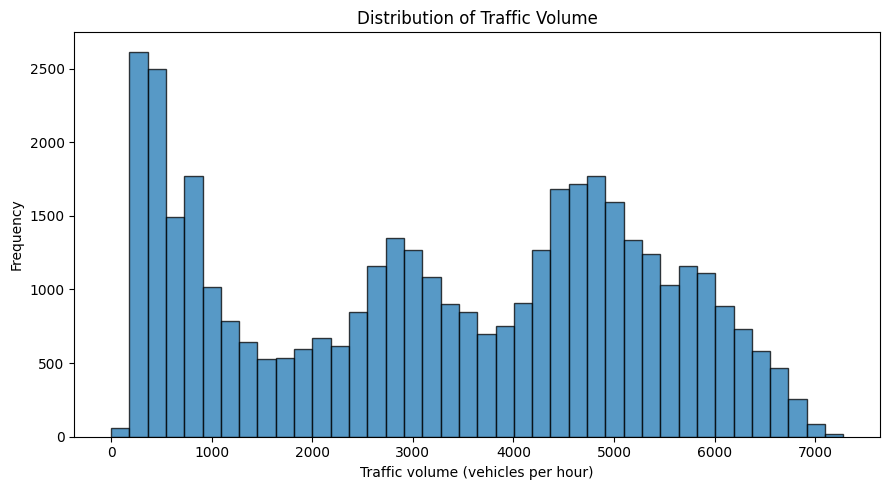

In [8]:
# Target distribution.
plt.figure(figsize=(9, 5))
plt.hist(hourly_df["traffic_volume"], bins=40, edgecolor="black", alpha=0.75)
plt.title("Distribution of Traffic Volume")
plt.xlabel("Traffic volume (vehicles per hour)")
plt.ylabel("Frequency")
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/traffic_volume_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

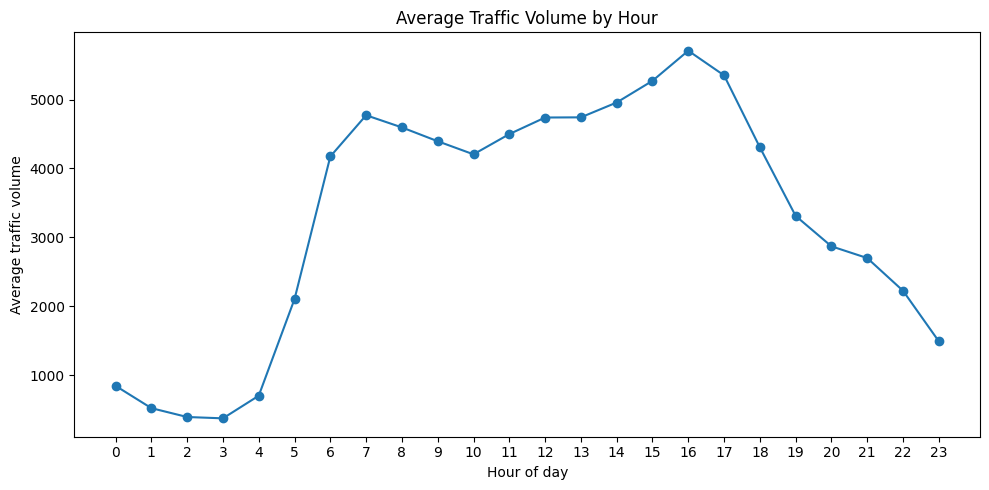

In [9]:
# Average traffic volume by hour of day.
hourly_traffic = hourly_df.groupby("hour")["traffic_volume"].mean()
plt.figure(figsize=(10, 5))
plt.plot(hourly_traffic.index, hourly_traffic.values, marker="o")
plt.title("Average Traffic Volume by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average traffic volume")
plt.xticks(range(24))
plt.tight_layout()
plt.savefig("images/traffic_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

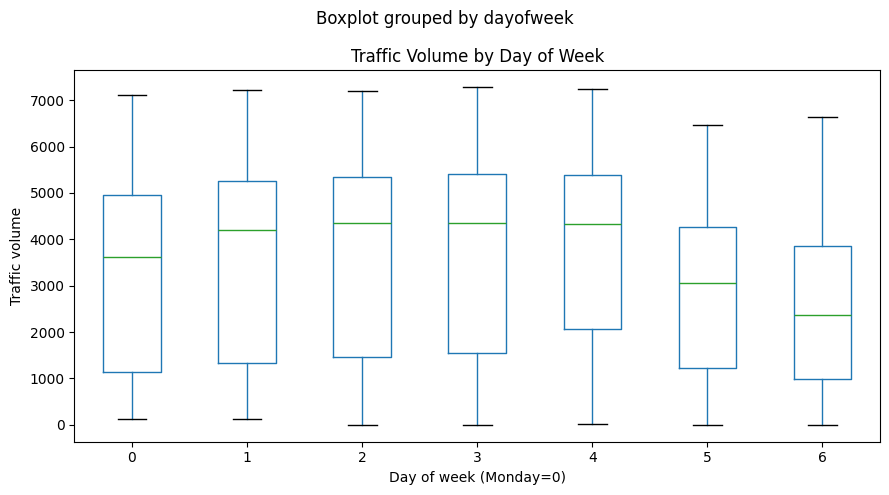

In [10]:
# Traffic volume by day of week.
plt.figure(figsize=(9, 5))
hourly_df.boxplot(column="traffic_volume", by="dayofweek", ax=plt.gca(), grid=False)
plt.title("Traffic Volume by Day of Week")
plt.xlabel("Day of week (Monday=0)")
plt.ylabel("Traffic volume")
plt.tight_layout()
plt.savefig("images/traffic_by_day_of_week.png", dpi=150, bbox_inches="tight")
plt.show()

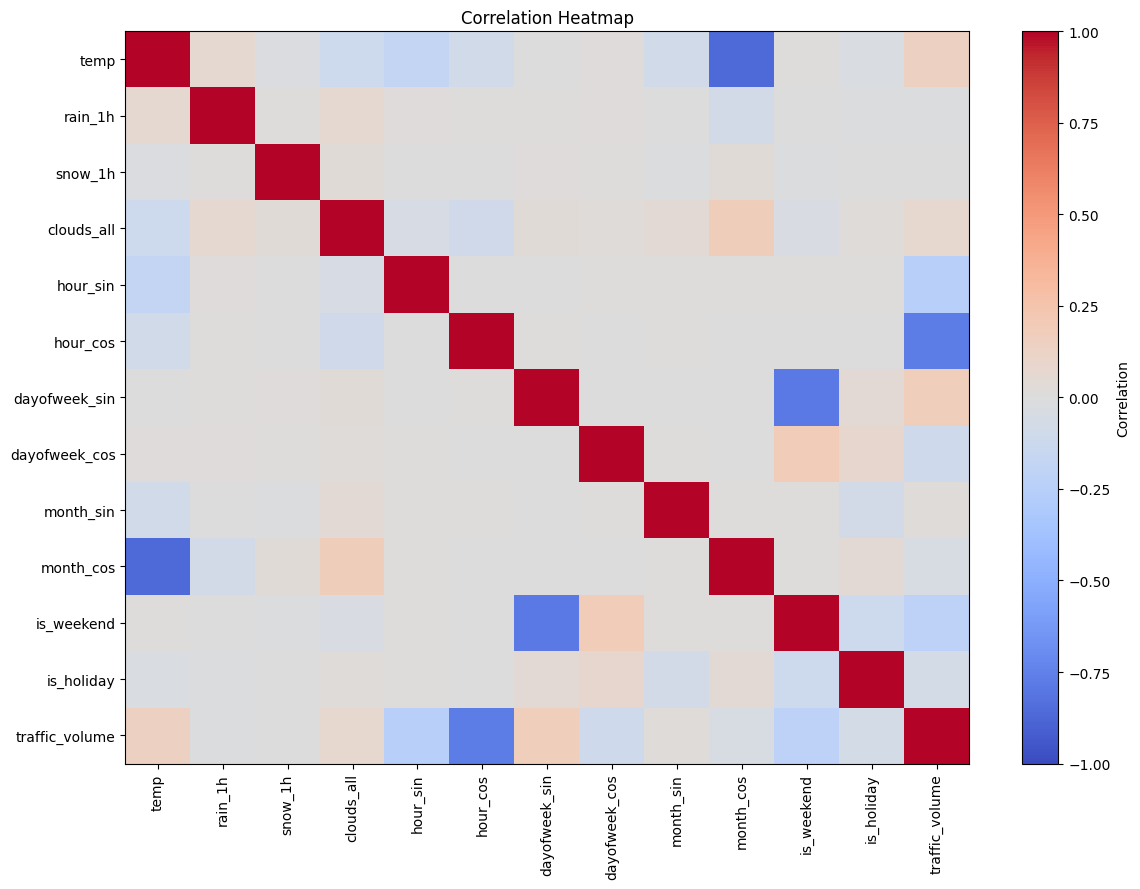

In [11]:
# Correlation between numeric variables.
numeric_for_corr = [
    "temp", "rain_1h", "snow_1h", "clouds_all",
    "hour_sin", "hour_cos", "dayofweek_sin", "dayofweek_cos",
    "month_sin", "month_cos", "is_weekend", "is_holiday",
    "traffic_volume"
]
plt.figure(figsize=(12, 9))
corr = hourly_df[numeric_for_corr].corr()
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Modeling setup

The data is split chronologically (70% train, 15% validation, 15% test) to respect time order. Preprocessing is fitted inside each model pipeline to avoid fitting scalers or encoders on validation/test data.

- `weather_main` is one-hot encoded rather than label-encoded as an artificial ordinal variable.
- Numeric features are standardized for Linear Regression, KNN, and SVR.
- Tree-based models use the same one-hot representation but do not require feature scaling.
- The hour is represented with sine/cosine features to capture the circular relationship between 23:00 and 00:00.

In [12]:
TARGET = "traffic_volume"
categorical_features = ["weather_main"]
numeric_features = [
    "temp", "rain_1h", "snow_1h", "clouds_all",
    "is_holiday", "is_weekend",
    "hour_sin", "hour_cos",
    "dayofweek_sin", "dayofweek_cos",
    "month_sin", "month_cos"
]
feature_columns = numeric_features + categorical_features

model_df = hourly_df.sort_values("date_time").reset_index(drop=True)
X = model_df[feature_columns]
y = model_df[TARGET]

n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Train dates:", model_df.date_time.iloc[0], "to", model_df.date_time.iloc[train_end - 1])
print("Validation dates:", model_df.date_time.iloc[train_end], "to", model_df.date_time.iloc[val_end - 1])
print("Test dates:", model_df.date_time.iloc[val_end], "to", model_df.date_time.iloc[-1])

Train: (28394, 13) (28394,)
Validation: (6085, 13) (6085,)
Test: (6085, 13) (6085,)
Train dates: 2012-10-02 09:00:00 to 2017-05-10 07:00:00
Validation dates: 2017-05-10 08:00:00 to 2018-01-19 16:00:00
Test dates: 2018-01-19 17:00:00 to 2018-09-30 23:00:00


In [13]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_transformer = Pipeline(numeric_steps)
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ])

def make_scaled_pipeline(estimator):
    return Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", estimator)
    ])

def make_tree_pipeline(estimator):
    return Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=False)),
        ("model", estimator)
    ])

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

## Model training

SVR with an RBF kernel can be computationally expensive on a large dataset. To keep this notebook practical on standard hardware, SVR is trained on a reproducible random sample of up to 6,000 training rows. Its validation and test metrics are still calculated on the full respective splits. This training-sample limitation is recorded in the results interpretation.

In [14]:
models = {
    "Linear Regression": make_scaled_pipeline(LinearRegression()),
    "Random Forest": make_tree_pipeline(RandomForestRegressor(
        n_estimators=200, max_depth=15, max_leaf_nodes=100,
        min_samples_split=5, min_samples_leaf=2,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=-1
    )),
    "Decision Tree": make_tree_pipeline(DecisionTreeRegressor(
        max_depth=15, min_samples_leaf=2, random_state=RANDOM_STATE
    )),
    "KNN": make_scaled_pipeline(KNeighborsRegressor(n_neighbors=5)),
    "SVR": make_scaled_pipeline(TransformedTargetRegressor(
        regressor=SVR(kernel="rbf", C=10, epsilon=0.1),
        transformer=StandardScaler()
    )),
    "AdaBoost": make_tree_pipeline(AdaBoostRegressor(
        n_estimators=100, learning_rate=0.05, random_state=RANDOM_STATE
    ))
}

# Fit all models. SVR uses a fixed-size reproducible training sample.
fitted_models = {}
for model_name, model in models.items():
    print(f"Training {model_name}...")
    if model_name == "SVR" and len(X_train) > 6000:
        svr_sample = X_train.sample(n=6000, random_state=RANDOM_STATE)
        svr_y_sample = y_train.loc[svr_sample.index]
        model.fit(svr_sample, svr_y_sample)
        print(f"  SVR training rows: {len(svr_sample):,} (sampled from {len(X_train):,})")
    else:
        model.fit(X_train, y_train)
    fitted_models[model_name] = model

Training Linear Regression...
Training Random Forest...


Training Decision Tree...
Training KNN...
Training SVR...


  SVR training rows: 6,000 (sampled from 28,394)
Training AdaBoost...


In [15]:
# Compare all models on the validation set.
validation_rows = []
for model_name, model in fitted_models.items():
    predictions = model.predict(X_val)
    validation_rows.append({"Model": model_name, **regression_metrics(y_val, predictions)})

validation_results = pd.DataFrame(validation_rows).sort_values("R2 Score", ascending=False)
display(validation_results.round(4))

,Model,MAE,RMSE,R2 Score
1,Random Forest,256.1765,412.6756,0.9559
2,Decision Tree,289.2203,491.4893,0.9375
4,SVR,391.6060,547.1882,0.9225
3,KNN,399.5058,592.4236,0.9092
5,AdaBoost,550.0659,703.3447,0.8720
0,Linear Regression,830.2800,1066.2386,0.7058


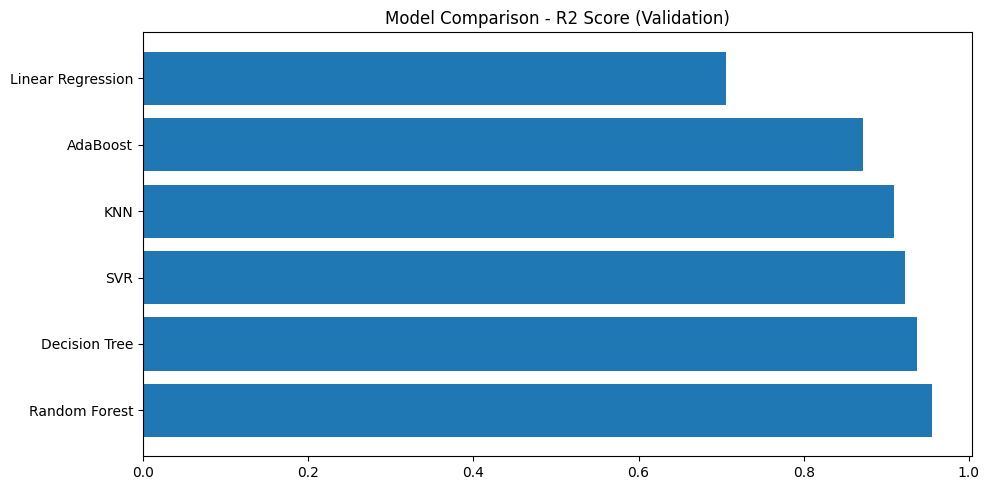

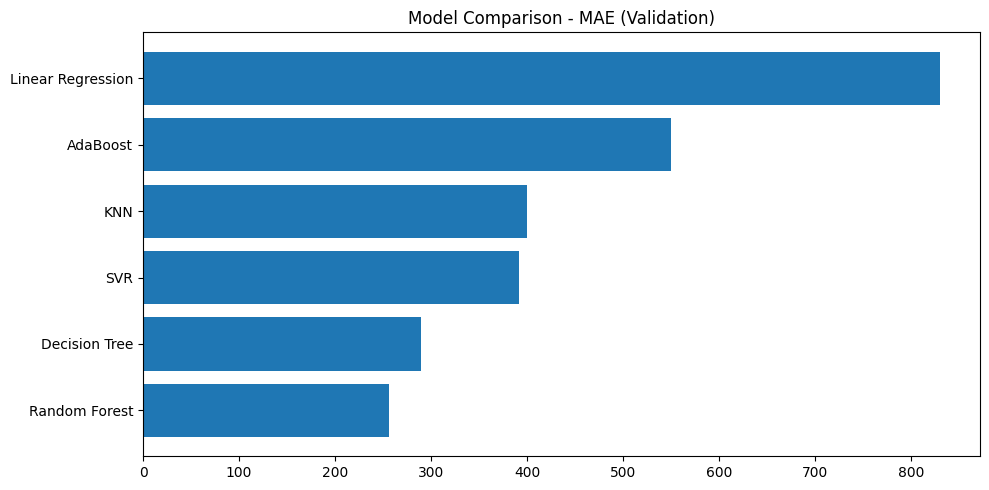

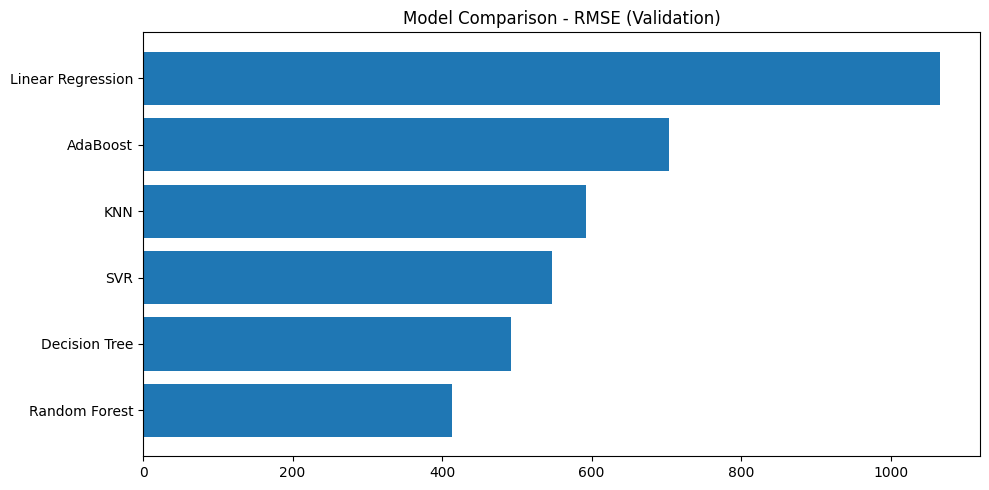

In [16]:
# Visual comparison on validation data.
for metric in ["R2 Score", "MAE", "RMSE"]:
    plot_data = validation_results.sort_values(metric, ascending=(metric != "R2 Score"))
    plt.figure(figsize=(10, 5))
    plt.barh(plot_data["Model"], plot_data[metric])
    plt.title(f"Model Comparison - {metric} (Validation)")
    plt.tight_layout()
    plt.savefig(f"images/model_comparison_{metric.lower().replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Time-aware Stacking Regressor

A standard shuffled K-fold stacking setup can mix future observations into the meta-model's training predictions. The following implementation creates out-of-fold predictions using expanding-window `TimeSeriesSplit`: each base model is trained only on earlier observations and predicts the next time block. The meta-model is trained on these chronological out-of-fold predictions.

In [17]:
class TimeAwareStackingRegressor:
    def __init__(self, base_estimators, final_estimator=None, n_splits=3):
        self.base_estimators = base_estimators
        self.final_estimator = final_estimator or Ridge(alpha=1.0)
        self.n_splits = n_splits

    def fit(self, X, y):
        splitter = TimeSeriesSplit(n_splits=self.n_splits)
        oof_predictions = np.full((len(X), len(self.base_estimators)), np.nan)

        for train_idx, valid_idx in splitter.split(X):
            for col, (name, estimator) in enumerate(self.base_estimators):
                fitted = clone(estimator)
                fitted.fit(X.iloc[train_idx], y.iloc[train_idx])
                oof_predictions[valid_idx, col] = fitted.predict(X.iloc[valid_idx])

        self.oof_mask_ = np.isfinite(oof_predictions).all(axis=1)
        self.oof_predictions_ = oof_predictions[self.oof_mask_]
        self.oof_target_ = y.iloc[np.flatnonzero(self.oof_mask_)]

        self.final_estimator_ = clone(self.final_estimator)
        self.final_estimator_.fit(self.oof_predictions_, self.oof_target_)

        self.fitted_base_estimators_ = []
        for name, estimator in self.base_estimators:
            fitted = clone(estimator)
            fitted.fit(X, y)
            self.fitted_base_estimators_.append((name, fitted))
        return self

    def predict(self, X):
        base_predictions = np.column_stack([
            estimator.predict(X) for _, estimator in self.fitted_base_estimators_
        ])
        return self.final_estimator_.predict(base_predictions)

stack_base_estimators = [
    ("rf", make_tree_pipeline(RandomForestRegressor(
        n_estimators=100, max_depth=15, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ))),
    ("knn", make_scaled_pipeline(KNeighborsRegressor(n_neighbors=5))),
    ("dt", make_tree_pipeline(DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=2, random_state=RANDOM_STATE
    )))
]

stacking_model = TimeAwareStackingRegressor(
    base_estimators=stack_base_estimators,
    final_estimator=Ridge(alpha=1.0),
    n_splits=3
)
print("Training time-aware stacking model...")
stacking_model.fit(X_train, y_train)
print(f"Meta-model training observations from chronological OOF folds: {len(stacking_model.oof_target_):,}")

Training time-aware stacking model...


Meta-model training observations from chronological OOF folds: 21,294


In [18]:
# Final evaluation: validation and test are evaluated on their full chronological splits.
# For the training metric of the time-aware stack, use only its out-of-fold rows.
evaluation_rows = []

for model_name, model in fitted_models.items():
    for split_name, X_split, y_split in [
        ("Train", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test)
    ]:
        pred = model.predict(X_split)
        evaluation_rows.append({
            "Model": model_name,
            "Dataset": split_name,
            **regression_metrics(y_split, pred)
        })

# Stacking: training metrics are calculated on chronological out-of-fold rows only.
stack_train_pred = stacking_model.final_estimator_.predict(stacking_model.oof_predictions_)
evaluation_rows.append({
    "Model": "Time-aware Stacking",
    "Dataset": "Train (OOF)",
    **regression_metrics(stacking_model.oof_target_, stack_train_pred)
})

for split_name, X_split, y_split in [
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    pred = stacking_model.predict(X_split)
    evaluation_rows.append({
        "Model": "Time-aware Stacking",
        "Dataset": split_name,
        **regression_metrics(y_split, pred)
    })

final_results = pd.DataFrame(evaluation_rows)
final_results[["MAE", "RMSE", "R2 Score"]] = final_results[["MAE", "RMSE", "R2 Score"]].round(4)
display(final_results)
final_results.to_csv("all_models_comparison.csv", index=False)

,Model,Dataset,MAE,RMSE,R2 Score
0,Linear Regression,Train,827.7382,1067.9504,0.7118
1,Linear Regression,Validation,830.2800,1066.2386,0.7058
2,Linear Regression,Test,831.5731,1059.3363,0.7136
3,Random Forest,Train,266.1027,413.3545,0.9568
4,Random Forest,Validation,256.1765,412.6756,0.9559
5,Random Forest,Test,240.5480,388.1396,0.9615
6,Decision Tree,Train,169.7878,278.6076,0.9804
7,Decision Tree,Validation,289.2203,491.4893,0.9375
8,Decision Tree,Test,273.6606,480.4033,0.9411
9,KNN,Train,308.7865,460.5417,0.9464


,Feature,Importance
7,numeric__hour_cos,0.705722
6,numeric__hour_sin,0.168525
8,numeric__dayofweek_sin,0.055082
5,numeric__is_weekend,0.041164
4,numeric__is_holiday,0.012847
9,numeric__dayofweek_cos,0.006184
0,numeric__temp,0.003911
10,numeric__month_sin,0.002416
11,numeric__month_cos,0.002396
1,numeric__rain_1h,0.000670


Combined hour feature importance: 0.8742
Combined weather category importance: 0.0005


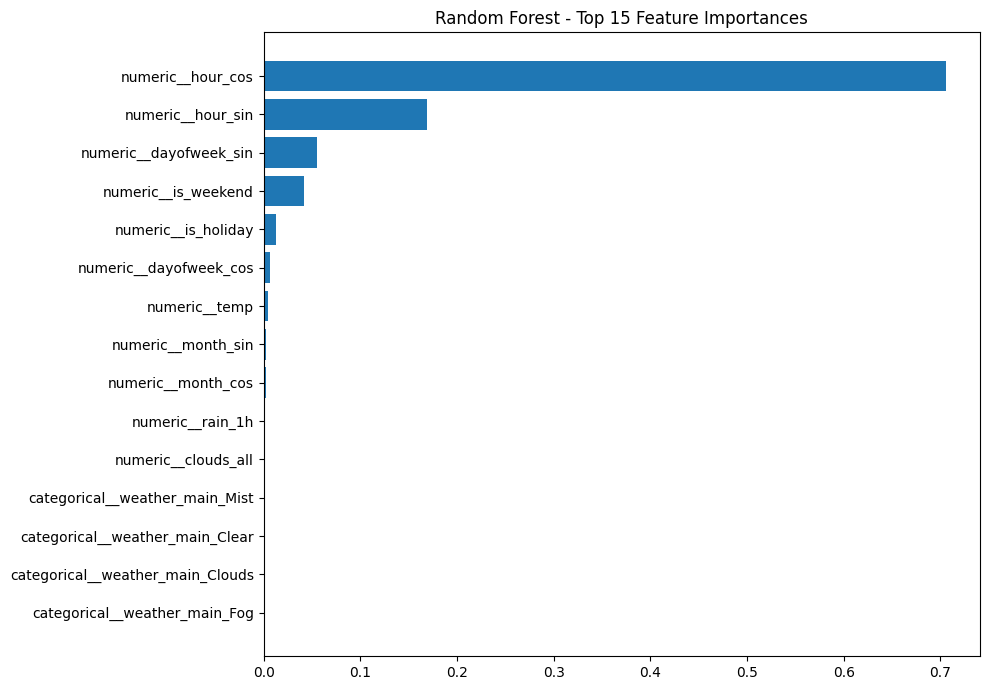

In [19]:
# Feature importance from the fitted Random Forest.
rf_pipeline = fitted_models["Random Forest"]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

feature_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
      .sort_values("Importance", ascending=False)
)
display(feature_importance.head(15))

# Aggregate importances by feature family for a compact interpretation.
weather_importance = feature_importance.loc[
    feature_importance["Feature"].str.startswith("categorical__"), "Importance"
].sum()
hour_importance = feature_importance.loc[
    feature_importance["Feature"].str.contains("hour_"), "Importance"
].sum()
print(f"Combined hour feature importance: {hour_importance:.4f}")
print(f"Combined weather category importance: {weather_importance:.4f}")

plt.figure(figsize=(10, 7))
top_features = feature_importance.head(15).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Summarize the key observations from the new run.
best_validation = validation_results.iloc[0]
test_results = final_results[final_results["Dataset"] == "Test"].sort_values("R2 Score", ascending=False)

print("Best validation model:", best_validation["Model"])
print("Validation R2:", round(best_validation["R2 Score"], 4))
print("\\nTop test results:")
display(test_results[["Model", "MAE", "RMSE", "R2 Score"]].head(5))
print("\\nTop feature importances:")
display(feature_importance.head(10))


Best validation model: Random Forest
Validation R2: 0.9559
\nTop test results:


,Model,MAE,RMSE,R2 Score
20,Time-aware Stacking,243.8224,386.5766,0.9619
5,Random Forest,240.5480,388.1396,0.9615
8,Decision Tree,273.6606,480.4033,0.9411
14,SVR,381.8844,529.1086,0.9285
11,KNN,390.2469,589.0702,0.9114


\nTop feature importances:


,Feature,Importance
7,numeric__hour_cos,0.705722
6,numeric__hour_sin,0.168525
8,numeric__dayofweek_sin,0.055082
5,numeric__is_weekend,0.041164
4,numeric__is_holiday,0.012847
9,numeric__dayofweek_cos,0.006184
0,numeric__temp,0.003911
10,numeric__month_sin,0.002416
11,numeric__month_cos,0.002396
1,numeric__rain_1h,0.000670


## Limitations

- This is a historical dataset for one highway direction and location; performance may not generalize to other roads or regions.
- Repeated timestamps are consolidated into one hourly row. Weather categories for the same timestamp can differ, so the mode is used as a representative category.
- The source dataset is not guaranteed to be a perfectly continuous hourly time series. This notebook does not create lag features, and time gaps should be considered before attempting sequence-based forecasting.
- SVR is trained on a reproducible 6,000-row sample for computational practicality; its results are not directly equivalent to a full-data SVR fit.
- Feature importance indicates predictive contribution within the fitted Random Forest; it does not establish causation.
- Model selection uses the validation set. The test set is reserved for final evaluation and should not be repeatedly used for tuning.